# 3 · Bedding, the representative elementary volume and upscaling (calibrated on Zeerijp-3A)

**Question.** Plugs are 3.8 cm across; reservoir grid blocks are tens of metres. At what size does permeability stop depending on the sample (the *representative elementary volume*, REV), and how wrong are plug values for vertical flow?

**Method** (after Nordahl and Ringrose, 2008). Synthetic two-component bedding models, sand and mud, from sand-rich (flaser) to mud-rich (lenticular), 1 m x 1 m at 5 mm cells. Sand and mud permeabilities come from the Zeerijp-3A plugs. For windows of growing size the effective kx and kz are computed by solving single-phase flow (no-flow sides). The variation between ten realisations shows when the REV is reached.

This is the core of an SBED-style workflow (core → bedding model → flow-based upscaling → REV), built with open tools only.

In [1]:
import json, pathlib, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, lasio
import subsurface_tools as kt
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
pathlib.Path("results").mkdir(exist_ok=True); pathlib.Path("figures").mkdir(exist_ok=True)
core_file = kt.fetch_nlog("core"); log_file = kt.fetch_nlog("logs"); sonic_file = kt.fetch_nlog("sonic")
plugs = kt.read_zrp_plugs(core_file)
print(len(plugs), "plug measurements from", plugs.sheet.nunique(), "sheets")
r = plugs.remark.astype(str).str.lower()
clean = plugs[(plugs.orient == "H") & plugs.k_kl.notna() & ~plugs.damaged & r.str.contains("sst") & ~r.str.contains("lam|cement")]
clay = plugs[r.str.contains("claystone|siltstone") & ~r.str.contains("clast")]
k_sand = float(clean.k_kl.median()); k_mud = 0.005   # most claystone plugs are below the 0.01 mD detection limit
print(f"clean sandstone plugs: {len(clean)}, median k {k_sand:.1f} mD; claystone/siltstone plugs: {len(clay)}, "
      f"{int(clay.k_below_detection.sum())} below 0.01 mD -> mud k set to {k_mud} mD")

633 plug measurements from 4 sheets
clean sandstone plugs: 16, median k 46.4 mD; claystone/siltstone plugs: 20, 9 below 0.01 mD -> mud k set to 0.005 mD


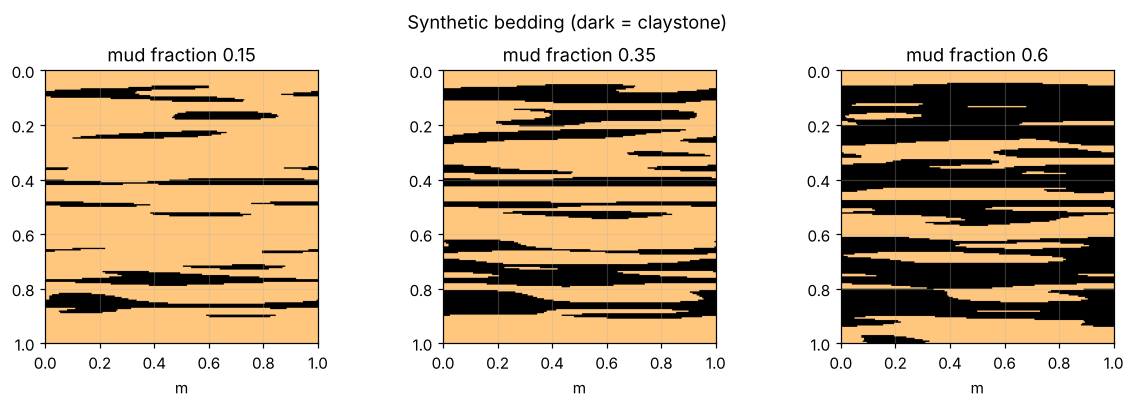

In [2]:
mud_fractions = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]; sizes = np.unique(np.round(np.geomspace(6, 200, 14)).astype(int)); cell = 0.005; NR = 10
fig, ax = plt.subplots(1, 3, figsize=(11, 3.6))
for a_, mf in zip(ax, [0.15, 0.35, 0.6]):
    a_.imshow(kt.bedding(200, 200, mf, seed=3), cmap="copper_r", extent=[0, 1, 1, 0]); a_.set_title(f"mud fraction {mf}"); a_.set_xlabel("m")
fig.suptitle("Synthetic bedding (dark = claystone)"); fig.tight_layout(); fig.savefig("figures/bedding_models.png")

In [3]:
rows = []
for mf in mud_fractions:
    for rlz in range(NR):
        mud = kt.bedding(200, 200, mf, seed=1000 * int(mf * 10) + rlz)
        rs = kt.rev_scan(np.where(mud, k_mud, k_sand), sizes); rs["mud"] = mf; rs["rlz"] = rlz; rows.append(rs)
R = pd.concat(rows); R["size_m"] = R.cells * cell
stats = R.groupby(["mud", "size_m"]).agg(kx=("kx", "mean"), kz=("kz", "mean"), cvx=("kx", lambda s: s.std() / s.mean()),
                                          cvz=("kz", lambda s: s.std() / s.mean())).reset_index()
def rev(cv, th):
    for i in range(len(cv)):
        if (cv.values[i:] < th).all(): return float(cv.index[i])
    return None
summary = []
for mf, g in stats.groupby("mud"):
    g = g.set_index("size_m"); plug = R[(R.mud == mf) & (R.cells == sizes[0])]; full = g.iloc[-1]
    summary.append({"mud fraction": mf, "kx 1 m (mD)": round(full.kx, 2), "kz 1 m (mD)": round(full.kz, 4), "kv/kh 1 m": round(full.kz / full.kx, 5),
                    "REV kx (m)": rev(g.cvx, 0.1), "REV kz (m)": rev(g.cvz, 0.5),
                    "plug kz P90 / bed kz": round(float(plug.kz.quantile(.9) / full.kz), 1)})
summary = pd.DataFrame(summary); print(summary.to_string(index=False))

 mud fraction  kx 1 m (mD)  kz 1 m (mD)  kv/kh 1 m  REV kx (m)  REV kz (m)  plug kz P90 / bed kz
          0.1        41.15       2.5764    0.06261       0.260         NaN                  18.0
          0.2        35.16       0.0804    0.00229       0.585         NaN                 577.5
          0.3        29.56       0.0282    0.00095       0.585       0.340                1647.7
          0.4        24.28       0.0192    0.00079         NaN       0.585                2421.6
          0.5        16.82       0.0139    0.00082         NaN       0.115                3348.2
          0.6        12.06       0.0100    0.00083         NaN       0.200                 464.9


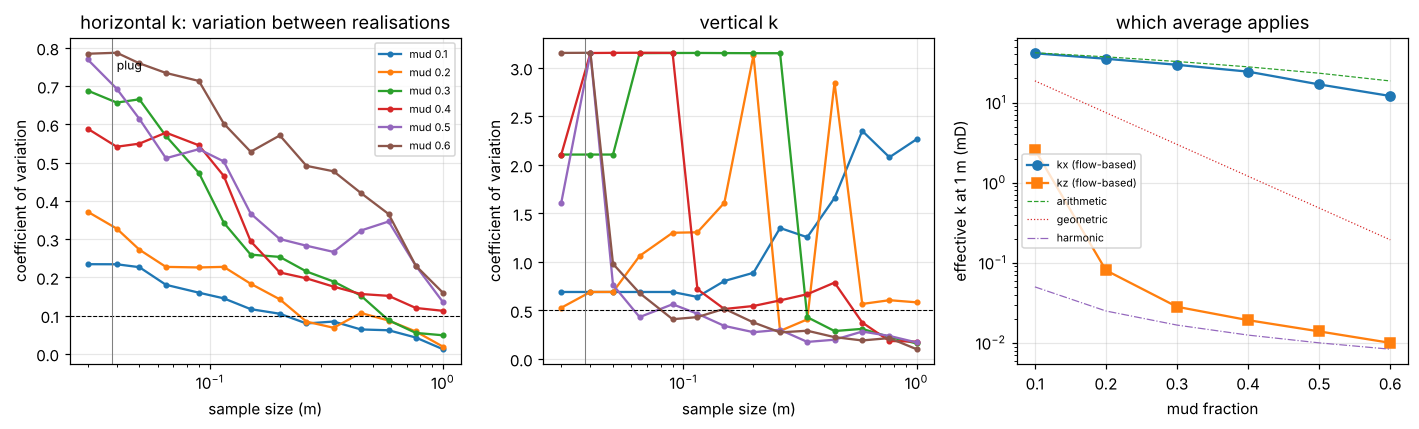

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for mf, g in stats.groupby("mud"):
    ax[0].semilogx(g.size_m, g.cvx, "o-", ms=3, label=f"mud {mf}"); ax[1].semilogx(g.size_m, g.cvz, "o-", ms=3)
ax[0].axhline(.1, color="k", lw=.7, ls="--"); ax[1].axhline(.5, color="k", lw=.7, ls="--")
ax[0].set_title("horizontal k: variation between realisations"); ax[1].set_title("vertical k"); ax[0].legend(fontsize=7)
for a_ in ax[:2]: a_.set_xlabel("sample size (m)"); a_.set_ylabel("coefficient of variation"); a_.axvline(0.038, color="grey", lw=.7)
ax[0].text(.04, ax[0].get_ylim()[1] * .9, "plug", fontsize=8)
m_ = np.array(mud_fractions); ari = (1 - m_) * k_sand + m_ * k_mud; har = 1 / ((1 - m_) / k_sand + m_ / k_mud); geo = k_sand ** (1 - m_) * k_mud ** m_
ax[2].semilogy(m_, summary["kx 1 m (mD)"], "o-", label="kx (flow-based)"); ax[2].semilogy(m_, summary["kz 1 m (mD)"], "s-", label="kz (flow-based)")
ax[2].semilogy(m_, ari, "--", lw=.8, label="arithmetic"); ax[2].semilogy(m_, geo, ":", lw=.8, label="geometric"); ax[2].semilogy(m_, har, "-.", lw=.8, label="harmonic")
ax[2].set_xlabel("mud fraction"); ax[2].set_ylabel("effective k at 1 m (mD)"); ax[2].legend(fontsize=7); ax[2].set_title("which average applies")
fig.tight_layout(); fig.savefig("figures/rev_upscaling.png")

In [5]:
summary.to_csv("results/rev_summary.csv", index=False)
json.dump({"k_sand_mD": round(k_sand, 2), "k_mud_mD": k_mud, "cell_m": cell, "realisations": NR, "summary": summary.to_dict("records")},
          open("results/nb3_rev.json", "w"), indent=1, default=float)
assert summary["kv/kh 1 m"].max() < 0.1

## Result and limits
* Horizontal permeability settles within decimetres in sand-rich bedding and follows the arithmetic average; it needs a metre or more once mud makes up half the rock.
* Vertical permeability is the problem. A plug cut in sandstone can overstate the bed-scale kz by two to four orders of magnitude (column `plug kz P90 / bed kz`), and bed-scale kv/kh falls far below the plug value of about 1 (notebook 1). kz moves from near the geometric towards the harmonic average as mud increases: the flow upscaling regimes of Ringrose et al. (2003).
* Limits: 2D sections, two components, one lens geometry; real bedding templates come from core description, and 3D connectivity raises kz somewhat. The workflow, not these exact numbers, is what transfers to a client's core.

*References:* Nordahl, K. and Ringrose, P.S. (2008) Math. Geosci. 40, 753-771 · Ringrose, P.S. et al. (2003) Petroleum Geoscience 9, 13-23.